In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt

In [2]:
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction import DictVectorizer
from sklearn.linear_model import LogisticRegression

In [3]:
!wget -O data.csv https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/course_lead_scoring_2026.csv

"wget" ­Ґ пў«пҐвбп ў­гваҐ­­Ґ© Ё«Ё ў­Ґи­Ґ©
Є®¬ ­¤®©, ЁбЇ®«­пҐ¬®© Їа®Ја ¬¬®© Ё«Ё Ї ЄҐв­л¬ д ©«®¬.


In [4]:
df = pd.read_csv('data.csv')

In [5]:
df

,lead_source,industry,employment_status,location,annual_income,number_of_courses_viewed,interaction_count,lead_score,converted
0,organic_search,technology,employed,europe,88160.0,3,4,0.64,1
1,social_media,technology,employed,south_america,72688.0,3,7,0.72,1
2,referral,retail,employed,europe,44697.0,3,4,0.58,1
3,paid_ads,manufacturing,student,NaN,NaN,3,6,0.57,0
4,referral,manufacturing,student,north_america,24062.0,4,5,0.62,1
...,...,...,...,...,...,...,...,...,...
4995,organic_search,education,employed,asia,45834.0,2,2,0.37,1
4996,NaN,technology,employed,north_america,84831.0,2,5,0.51,0
4997,organic_search,finance,employed,asia,53636.0,4,6,0.75,1
4998,referral,technology,employed,africa,69430.0,4,8,0.79,1


In [6]:
str_cols = df.select_dtypes(include=['object', 'string']).columns
df[str_cols] = df[str_cols].fillna('NA')

In [7]:
num_cols = df.select_dtypes(include=['number']).columns
df[num_cols] = df[num_cols].fillna(0.0)

In [8]:
df.columns = df.columns.str.lower().str.replace(' ', '_')

In [9]:
df.dtypes

lead_source                     str
industry                        str
employment_status               str
location                        str
annual_income               float64
number_of_courses_viewed      int64
interaction_count             int64
lead_score                  float64
converted                     int64
dtype: object

In [10]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(df_full_train, test_size=0.25, random_state=1)

In [11]:
numerical = ['annual_income', 'number_of_courses_viewed', 'interaction_count', 'lead_score']

In [12]:
categorical = ['lead_source', 'industry', 'employment_status', 'location']

In [13]:
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

In [14]:
y_train = df_train.converted.values
y_val = df_val.converted.values
y_test = df_test.converted.values

In [15]:
del df_train['converted']
del df_val['converted']
del df_test['converted']

In [16]:
dv = DictVectorizer(sparse=False)

train_dict = df_train[categorical + numerical].to_dict(orient='records')
X_train = dv.fit_transform(train_dict)

In [17]:
model = LogisticRegression(solver='liblinear', C=1.0, max_iter=1000)

In [18]:
model.fit(X_train, y_train)

,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class of problems.- For :term:`multiclass` problems (`n_classes >= 3`), all solvers except 'liblinear' minimize the full multinomial loss, 'liblinear' will raise an error.- 'newton-cholesky' is a good choice for `n_samples` >> `n_features * n_classes`, especially with one-hot encoded categorical features with rare categories. Be aware that the memory usage of this solver has a quadratic dependency on `n_features * n_classes` because it explicitly computes the full Hessian matrix.- For small datasets, 'liblinear' is a good choice, whereas 'sag' and 'saga' are faster for large ones;- 'liblinear' can only handle binary classification by default. To apply a one-versus-rest scheme for the multiclass setting one can wrap it with the :class:`~sklearn.multiclass.OneVsRestClassifier`... warning:: The choice of the algorithm depends on the penalty chosen (`l1_ratio=0` for L2-penalty, `l1_ratio=1` for L1-penalty and `0 < l1_ratio < 1` for Elastic-Net) and on (multinomial) multiclass support: ================= ======================== ====================== solver l1_ratio multinomial multiclass ================= ======================== ====================== 'lbfgs' l1_ratio=0 yes 'liblinear' l1_ratio=1 or l1_ratio=0 no 'newton-cg' l1_ratio=0 yes 'newton-cholesky' l1_ratio=0 yes 'sag' l1_ratio=0 yes 'saga' 0<=l1_ratio<=1 yes ================= ======================== ======================.. note:: 'sag' and 'saga' fast convergence is only guaranteed on features with approximately the same scale. You can preprocess the data with a scaler from :mod:`sklearn.preprocessing`... seealso:: Refer to the :ref:`User Guide <Logistic_regression>` for more information regarding :class:`LogisticRegression` and more specifically the :ref:`Table <logistic_regression_solvers>` summarizing solver/penalty supports... versionadded:: 0.17 Stochastic Average Gradient (SAG) descent solver. Multinomial support in version 0.18... versionadded:: 0.19 SAGA solver... versionchanged:: 0.22 The default solver changed from 'liblinear' to 'lbfgs' in 0.22... versionadded:: 1.2 newton-cholesky solver. Multinomial support in version 1.6.",'liblinear'
,"max_iter max_iter: int, default=100Maximum number of iterations taken for the solvers to converge.",1000
,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add an L2 penalty term and it is the default choice;- `'l1'`: add an L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` and `C` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'`, `l1_ratio` set to any float between 0 and 1 for `penalty='elasticnet'`, and `C=np.inf` for `penalty=None`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",1.0
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalt

In [19]:
val_dict = df_val[categorical + numerical].to_dict(orient='records')
X_val = dv.transform(val_dict)

In [20]:
from sklearn.metrics import roc_auc_score
y_pred = model.predict_proba(X_val)[:, 1]
auc = roc_auc_score(y_val, y_pred)
converted_decision = (y_pred >= 0.5)
(y_val == converted_decision).mean()


np.float64(0.651)

In [21]:
from sklearn.metrics import roc_auc_score

In [22]:
aucs = {}
for col in numerical:
    auc = roc_auc_score(y_train, df_train[col])
    if auc < 0.5:
        auc = roc_auc_score(y_train, -df_train[col])
    aucs[col] = auc
print(pd.Series(aucs))

annual_income               0.608198
number_of_courses_viewed    0.722989
interaction_count           0.764920
lead_score                  0.788225
dtype: float64


In [23]:
from sklearn.metrics import accuracy_score

In [24]:
accuracy_score(y_val, y_pred >= 0.5)

0.651

In [25]:
thresholds = np.linspace(0, 1, 21)

scores = []

for t in thresholds:
    score = accuracy_score(y_val, y_pred >= t)
    print('%.2f %.3f' % (t, score))
    scores.append(score)

0.00 0.586
0.05 0.586
0.10 0.586
0.15 0.586
0.20 0.586
0.25 0.586
0.30 0.597
0.35 0.613
0.40 0.625
0.45 0.640
0.50 0.651
0.55 0.661
0.60 0.681
0.65 0.669
0.70 0.643
0.75 0.590
0.80 0.530
0.85 0.468
0.90 0.432
0.95 0.416
1.00 0.414


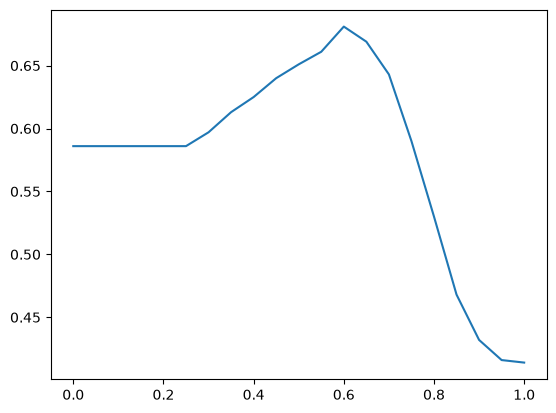

In [26]:
plt.plot(thresholds, scores)

In [27]:
from collections import Counter
Counter(y_pred >= 1.0)

Counter({np.False_: 1000})

In [28]:
1 - y_val.mean()

np.float64(0.41400000000000003)

In [29]:
actual_positive = (y_val == 1)
actual_negative = (y_val == 0)

In [30]:
t = 0.5
predict_positive = (y_pred >= t)
predict_negative = (y_pred < t)

In [31]:
tp = (predict_positive & actual_positive).sum()
tn = (predict_negative & actual_negative).sum()

fp = (predict_positive & actual_negative).sum()
fn = (predict_negative & actual_positive).sum()

In [32]:
confusion_matrix = np.array([
    [tn, fp],
    [fn, tp]
])
confusion_matrix

array([[120, 294],
       [ 55, 531]])

In [33]:
(confusion_matrix / confusion_matrix.sum()).round(3)

array([[0.12 , 0.294],
       [0.055, 0.531]])

In [34]:
pr = tp / (tp + fp)
pr

np.float64(0.6436363636363637)

In [35]:
rc = tp / (tp + fn)
rc

np.float64(0.9061433447098977)

In [36]:
# import numpy as np
# from sklearn.metrics import precision_score, recall_score

# y_pred_proba = model.predict_proba(X_val)[:, 1]
# y_val_arr = np.asarray(y_val)

# thresholds = np.arange(0.0, 1.01, 0.01)
# precisions, recalls = [], []

# for t in thresholds:
#     y_pred = (y_pred_proba >= t).astype(int)
#     precisions.append(precision_score(y_val_arr, y_pred, zero_division=0))
#     recalls.append(recall_score(y_val_arr, y_pred, zero_division=0))

# precisions = np.array(precisions)
# recalls    = np.array(recalls)

# # Маска: отбрасываем пороги, где обе = 0
# mask = (precisions > 0) | (recalls > 0)
# diff = np.abs(precisions[mask] - recalls[mask])
# best_threshold = thresholds[mask][diff.argmin()]

# print(f'Ответ: {best_threshold:.2f}')

In [37]:
# import numpy as np
# import pandas as pd
# import matplotlib.pyplot as plt
# from sklearn.metrics import precision_score, recall_score

# # 1) Вероятности на валидации
# y_pred_proba = model.predict_proba(X_val)[:, 1]
# y_val_arr = y_val.values if hasattr(y_val, 'values') else y_val

# # 2) Пороги от 0.0 до 1.0 с шагом 0.01
# thresholds = np.arange(0.0, 1.01, 0.01)

# precisions = []
# recalls = []

# for t in thresholds:
#     y_pred = (y_pred_proba >= t).astype(int)
#     p = precision_score(y_val_arr, y_pred, zero_division=0)
#     r = recall_score(y_val_arr, y_pred, zero_division=0)
#     precisions.append(p)
#     recalls.append(r)

# # 3) График
# plt.figure(figsize=(8, 6))
# plt.plot(thresholds, precisions, label='Precision', linewidth=2)
# plt.plot(thresholds, recalls,    label='Recall',    linewidth=2)
# plt.xlabel('Threshold')
# plt.ylabel('Score')
# plt.title('Precision vs Recall по порогам')
# plt.legend()
# plt.grid(True, alpha=0.3)
# plt.tight_layout()
# plt.savefig('precision_recall.png', dpi=150)
# plt.show()

# df_pr = pd.DataFrame({
#     'threshold': thresholds,
#     'precision': precisions,
#     'recall':    recalls,
# })

# # Отбрасываем пороги, где обе метрики = 0 (модель ничего не предсказывает)
# df_pr = df_pr[(df_pr['precision'] > 0) | (df_pr['recall'] > 0)].copy()

# # Абсолютная разница
# df_pr['diff'] = (df_pr['precision'] - df_pr['recall']).abs()

# # Порог с минимальной разницей
# best_row = df_pr.loc[df_pr['diff'].idxmin()]
# print(best_row)

# print(f"\nПорог пересечения: {best_row['threshold']:.2f}")
# print(f"Precision: {best_row['precision']:.3f}")
# print(f"Recall:    {best_row['recall']:.3f}")
# print(f"|P - R|:   {best_row['diff']:.4f}")

In [38]:
tpr = tp / (tp + fn)
tpr

np.float64(0.9061433447098977)

In [39]:
fpr = fp / (fp + tn)
fpr

np.float64(0.7101449275362319)

In [43]:
scores = []

thresholds = np.linspace(0, 1, 101)

for t in thresholds:
    actual_positive = (y_val == 1)
    actual_negative = (y_val == 0)
    
    predict_positive = (y_pred >= t)
    predict_negative = (y_pred < t)

    tp = (predict_positive & actual_positive).sum()
    tn = (predict_negative & actual_negative).sum()

    fp = (predict_positive & actual_negative).sum()
    fn = (predict_negative & actual_positive).sum()
    
    scores.append((t, tp, fp, fn, tn))

In [44]:
columns = ['threshold', 'tp', 'fp', 'fn', 'tn']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores['tpr'] = df_scores.tp / (df_scores.tp + df_scores.fn)
df_scores['fpr'] = df_scores.fp / (df_scores.fp + df_scores.tn)

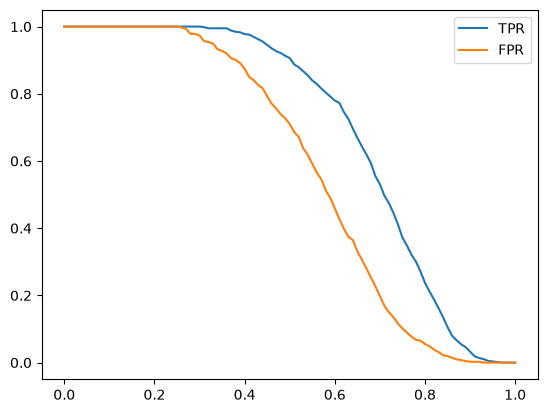

In [45]:
plt.plot(df_scores.threshold, df_scores['tpr'], label='TPR')
plt.plot(df_scores.threshold, df_scores['fpr'], label='FPR')
plt.legend()

In [46]:
df_scores['precision'] = df_scores.tp / (df_scores.tp + df_scores.fp)
df_scores['recall'] = df_scores.tp / (df_scores.tp + df_scores.fn)

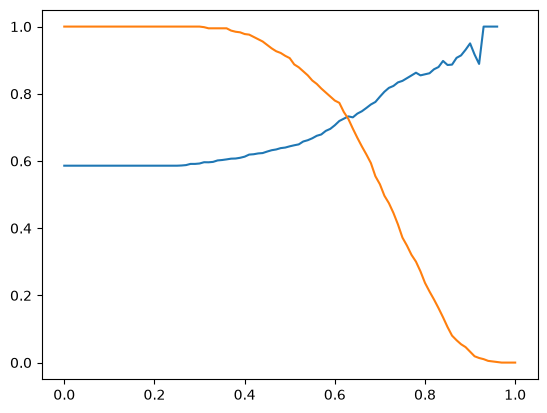

In [47]:
plt.plot(df_scores.threshold, df_scores['precision'], label='Precision')
plt.plot(df_scores.threshold, df_scores['recall'], label='Recall')

In [81]:
df_scores = df_scores[(df_scores['precision'] > 0) | (df_scores['recall'] > 0)].copy()

df_scores['diff'] = (df_scores['precision'] - df_scores['recall']).abs()

best_row = df_scores.loc[df_scores['diff'].idxmin()]
print(best_row)

print(best_row['threshold'])
print(best_row['precision'])
print(best_row['recall'])
print(best_row['diff'])

threshold      0.630000
tp           425.000000
fp           155.000000
fn           161.000000
tn           259.000000
tpr            0.725256
fpr            0.374396
precision      0.732759
recall         0.725256
diff           0.007503
f1             0.728988
Name: 63, dtype: float64
0.63
0.7327586206896551
0.7252559726962458
0.007502647993409384


In [65]:
df_scores['f1'] = 2 * df_scores['precision'] * df_scores['recall'] / ( df_scores['precision'] + df_scores['recall'])

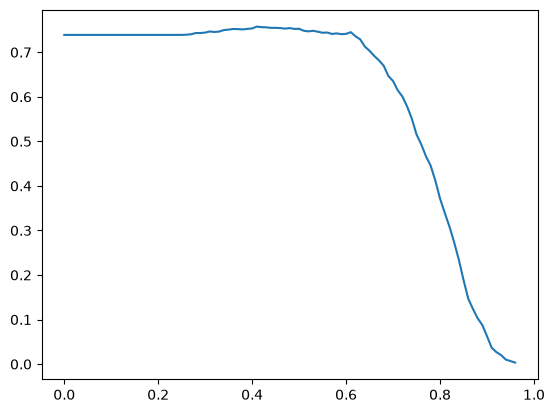

In [66]:
plt.plot(df_scores.threshold, df_scores['f1'])

In [67]:
best_idx = df_scores['f1'].argmax()
best_threshold = thresholds[best_idx]

In [84]:
df_scores['f1'].values[best_idx].round(5), best_threshold


(np.float64(0.75762), np.float64(0.41000000000000003))

In [85]:
from sklearn.model_selection import KFold

In [86]:
!pip install tqdm

In [89]:
def train(df_train, y_train, C=1.0):
    dicts = df_train[categorical + numerical].to_dict(orient='records')

    dv = DictVectorizer(sparse=False)
    X_train = dv.fit_transform(dicts)

    model = LogisticRegression(solver='liblinear', C=C, max_iter=1000)
    model.fit(X_train, y_train)
    
    return dv, model

In [90]:
def predict(df, dv, model):
    dicts = df[categorical + numerical].to_dict(orient='records')

    X = dv.transform(dicts)
    y_pred = model.predict_proba(X)[:, 1]

    return y_pred

In [91]:
dv, model = train(df_train, y_train, C=1.0)

In [92]:
y_pred = predict(df_val, dv, model)

In [105]:
kfold = KFold(n_splits=5, shuffle=True, random_state=1)

scores = []

for train_idx, val_idx in kfold.split(df_full_train):
    df_train = df_full_train.iloc[train_idx]
    df_val = df_full_train.iloc[val_idx]

    y_train = df_train.converted.values
    y_val = df_val.converted.values

    dv, model = train(df_train, y_train)
    y_pred = predict(df_val, dv, model)

    auc = roc_auc_score(y_val, y_pred)
    scores.append(auc)
np.mean(scores), np.std(scores).round(3)

(np.float64(0.7317269710972524), np.float64(0.007))

In [107]:
from tqdm.auto import tqdm

In [111]:
n_splits = 5

for C in tqdm([0.000001, 0.00001, 0.0001, 0.001, 0.01, 0.1, 1]):
    kfold = KFold(n_splits=n_splits, shuffle=True, random_state=1)

    scores = []

    for train_idx, val_idx in kfold.split(df_full_train):
        df_train = df_full_train.iloc[train_idx]
        df_val = df_full_train.iloc[val_idx]

        y_train = df_train.converted.values
        y_val = df_val.converted.values

        dv, model = train(df_train, y_train, C=C)
        y_pred = predict(df_val, dv, model)

        auc = roc_auc_score(y_val, y_pred)
        scores.append(auc)

    print('C=%s %.3f +- %.3f' % (C, np.mean(scores), np.std(scores)))

  0%|          | 0/7 [00:00<?, ?it/s]

C=1e-06 0.617 +- 0.019
C=1e-05 0.657 +- 0.022
C=0.0001 0.752 +- 0.015
C=0.001 0.749 +- 0.010
C=0.01 0.733 +- 0.007
C=0.1 0.732 +- 0.007
C=1 0.732 +- 0.007
